# Análise da Simulação SWGO — Múon de 5 GeV no WCD
**Dissertação de Mestrado em Física**

Simulação Geant4 11.1.3 — Múon vertical de 5 GeV  
Detector: WCD cilíndrico (r=170 cm, h=187.87 cm) com revestimento Tyvek  
4 PMTs (3 no fundo em triângulo equilátero + 1 no topo)

---

## 1. Importações e Configurações

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from scipy.optimize import curve_fit
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')

# Estilo acadêmico profissional
sns.set_theme(style='ticks', palette='colorblind')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 13,
    'axes.linewidth': 0.8,
    'axes.edgecolor': 'black',
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'legend.framealpha': 0.9,
    'legend.edgecolor': '0.8',
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

# ── Funções auxiliares ────────────────────────────────────────────────────────
def gaussian(x, A, mu, sigma):
    return A * np.exp(-0.5 * ((x - mu) / sigma) ** 2)

def landau_approx(x, A, mu, sigma):
    lam = (x - mu) / sigma
    return A * np.exp(-0.5 * (lam + np.exp(-lam))) / np.sqrt(2 * np.pi)

def format_value_error(val, err):
    if err == 0 or np.isnan(err):
        return f'{val:.2f}', '—'
    mag = int(np.floor(np.log10(abs(err))))
    decimals = max(0, -mag + 1)
    fmt = f'{{:.{decimals}f}}'
    return fmt.format(val), fmt.format(err)

def fit_and_plot(ax, data, bins, color, fit_func='gaussian', label='',
                 text_x=0.97, text_y=0.97, text_ha='right',
                 n_total=None, n_filtered=0):
    """Plota histograma com ajuste e parâmetros na caixa de texto"""
    counts, edges = np.histogram(data, bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    width = edges[1] - edges[0]
    
    ax.bar(centers, counts, width=width*0.9, color=color, alpha=0.8, 
       edgecolor='black', linewidth=0.5, label='Simulação')
    
    try:
        if fit_func == 'gaussian':
            p0 = [counts.max(), np.mean(data), np.std(data)]
            popt, pcov = curve_fit(gaussian, centers, counts, p0=p0, maxfev=5000)
            perr = np.sqrt(np.diag(pcov))
            x_fit = np.linspace(centers[0], centers[-1], 300)
            ax.plot(x_fit, gaussian(x_fit, *popt), color='#922B21', linewidth=1.5, label='Ajuste Gaussiano')
            mu_str, mu_err_str = format_value_error(popt[1], perr[1])
            sig_str, sig_err_str = format_value_error(abs(popt[2]), perr[2])
            n_display = n_total if n_total else len(data)
            textstr = (
                f'Dados do ajuste:\n'
                f'$\\mu$ = {mu_str} \u00b1 {mu_err_str}\n'
                f'$\\sigma$ = {sig_str} \u00b1 {sig_err_str}\n'
                f'N = {n_display}'
            )
            if n_filtered > 0:
                textstr += f'\n({n_filtered} outliers removidos)'

        elif fit_func == 'landau':
            p0 = [counts.max(), np.mean(data), np.std(data)]
            popt, pcov = curve_fit(landau_approx, centers, counts, p0=p0, maxfev=5000)
            perr = np.sqrt(np.diag(pcov))
            x_fit = np.linspace(centers[0], centers[-1], 300)
            ax.plot(x_fit, landau_approx(x_fit, *popt), color='#922B21', linewidth=1.5, label='Ajuste Landau')
            mpv_str, mpv_err_str = format_value_error(popt[1], perr[1])
            sig_str, sig_err_str = format_value_error(abs(popt[2]), perr[2])
            n_display = n_total if n_total else len(data)
            textstr = (
                f'Dados do ajuste:\n'
                f'MPV = {mpv_str} \u00b1 {mpv_err_str} MeV\n'
                f'$\\sigma$ = {sig_str} \u00b1 {sig_err_str} MeV\n'
                f'N = {n_display}'
            )
            if n_filtered > 0:
                textstr += f'\n({n_filtered} outliers removidos)'

        props = dict(boxstyle='round', facecolor='white', alpha=0.5)
        ax.text(text_x, text_y, textstr, transform=ax.transAxes, fontsize=10,
                verticalalignment='top', horizontalalignment=text_ha, bbox=props)
    except Exception as e:
        print(f'Ajuste falhou: {e}')
    
    return ax

## 2. Carregamento dos Dados

In [2]:
# Caminhos dos arquivos
#DATA_PATH = r'\\wsl.localhost\Ubuntu-20.04\home\ubuntu20\geant4-v11.1.3\2026\2026_build\SWGO_muon5GeV_vertical_1000ev_nt_Data.csv'
#PMT_PATH  = r'\\wsl.localhost\Ubuntu-20.04\home\ubuntu20\geant4-v11.1.3\2026\2026_build\SWGO_muon5GeV_vertical_1000ev_nt_PMTData.csv'
#HODO_PATH = r'\\wsl.localhost\Ubuntu-20.04\home\ubuntu20\geant4-v11.1.3\2026\2026_build\SWGO_muon5GeV_vertical_1000ev_nt_HodoData.csv'  

DATA_PATH = r'C:\Users\gizel\OneDrive\Área de Trabalho\Análises\Muon_vertical_com_otica\v05\Data\SWGO_muon5GeV_vertical_1000ev_nt_Data.csv'
PMT_PATH  = r'C:\Users\gizel\OneDrive\Área de Trabalho\Análises\Muon_vertical_com_otica\v05\Data\SWGO_muon5GeV_vertical_1000ev_nt_PMTData.csv'
HODO_PATH = r'C:\Users\gizel\OneDrive\Área de Trabalho\Análises\Muon_vertical_com_otica\v05\Data\SWGO_muon5GeV_vertical_1000ev_nt_HodoData.csv'

df = pd.read_csv(DATA_PATH, comment='#', header=None, names=[
    'iEventID', 'EnergyDeposited_MeV', 'PositionX_cm', 'PositionY_cm',
    'PositionZ_cm', 'Time_ns', 'EnergyElectronSec_MeV', 'nElectronSec',
    'nCerenkovByMuon', 'nCerenkovByElectron', 'EdepGammas_MeV', 'EdepTrack_MeV'
])

df_pmt = pd.read_csv(PMT_PATH, comment='#', header=None, names=[
    'iEventID', 'nFotonsPMT1', 'nFotonsPMT2', 'nFotonsPMT3', 'nFotonsPMT4'
])

# Total de fótons detectados
df_pmt['nFotonsTotal'] = df_pmt['nFotonsPMT1'] + df_pmt['nFotonsPMT2'] + df_pmt['nFotonsPMT3']

# Carrega hodoscópio
df_hodo = pd.read_csv(HODO_PATH, comment='#', header=None, names=[
    'iEventID', 'ColumnID', 'RowID', 'Edep_MeV', 'Time_ns'
])

# Merge
df_all = df.merge(df_pmt, on='iEventID')

# Total de fótons Cherenkov produzidos
df_all['nCerenkovTotal'] = df_all['nCerenkovByMuon'] + df_all['nCerenkovByElectron']

print(f'Eventos carregados: {len(df)}')
print(f'\nEstatísticas básicas:')
df[['EnergyDeposited_MeV', 'nCerenkovByMuon', 'nCerenkovByElectron', 'nElectronSec']].describe().round(2)

Eventos carregados: 1000

Estatísticas básicas:


,EnergyDeposited_MeV,nCerenkovByMuon,nCerenkovByElectron,nElectronSec
count,1000.00,1000.00,1000.00,1000.00
mean,409.81,62629.84,11939.64,43.56
std,74.74,259.17,7346.36,6.57
min,333.70,61646.00,1557.00,27.00
25%,368.66,62461.50,6808.50,39.00
50%,388.06,62623.00,9877.00,43.00
75%,424.79,62806.25,15093.00,48.00
max,1123.74,63603.00,52873.00,63.00


## 3. Energia Depositada — Distribuição de Landau

O múon de 5 GeV é uma **partícula mínimamente ionizante (MIP)** na água.  
A distribuição de energia depositada segue uma distribuição de **Landau** —  
assimétrica com cauda para altos valores, característica de partículas relativísticas.

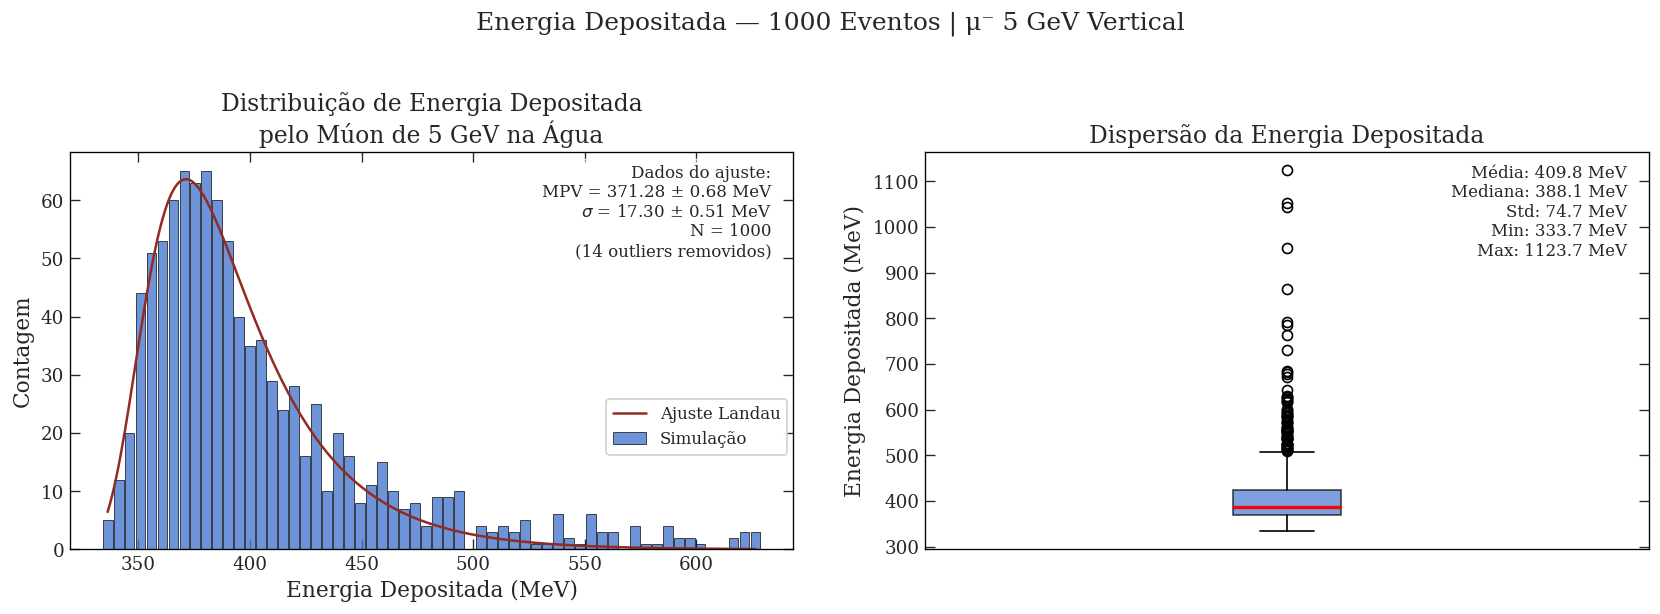

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = sns.color_palette('muted')

# Filtra outliers (>3 sigma) para o ajuste
edep = df['EnergyDeposited_MeV']
edep_filtered = edep[edep < edep.mean() + 3*edep.std()]

ax1 = axes[0]
#fit_and_plot(ax1, edep_filtered, bins=60, color=palette[0], fit_func='landau', text_x=0.97, text_ha='right')
#fit_and_plot(ax1, edep_filtered, bins=60, color=palette[0], fit_func='landau', text_x=0.97, text_y=0.97, text_ha='right')

fit_and_plot(ax1, edep_filtered, bins=60, color=palette[0], 
             fit_func='landau', text_x=0.97, text_y=0.97, text_ha='right',
             n_total=len(df), n_filtered=len(df)-len(edep_filtered))


ax1.set_xlabel('Energia Depositada (MeV)')
ax1.set_ylabel('Contagem')
ax1.set_title('Distribuição de Energia Depositada\npelo Múon de 5 GeV na Água')
#ax1.legend(fontsize=10)
#ax1.legend(fontsize=10, loc='lower right')
ax1.legend(fontsize=10, bbox_to_anchor=(0.73, 0.4), loc='upper left')

# Boxplot
ax2 = axes[1]
bp = ax2.boxplot(edep, patch_artist=True,
                 boxprops=dict(facecolor=palette[0], alpha=0.7),
                 medianprops=dict(color='red', linewidth=2))
ax2.set_ylabel('Energia Depositada (MeV)')
ax2.set_title('Dispersão da Energia Depositada')
ax2.set_xticks([])
textstr = (
    f'Média: {edep.mean():.1f} MeV\n'
    f'Mediana: {edep.median():.1f} MeV\n'
    f'Std: {edep.std():.1f} MeV\n'
    f'Min: {edep.min():.1f} MeV\n'
    f'Max: {edep.max():.1f} MeV'
)
props = dict(boxstyle='round', facecolor='white', alpha=0.8)
ax2.text(0.97, 0.97, textstr, transform=ax2.transAxes, fontsize=10,
         verticalalignment='top', horizontalalignment='right', bbox=props)

plt.suptitle('Energia Depositada — 1000 Eventos | μ⁻ 5 GeV Vertical', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('energia_depositada.png')
plt.show()

## 4. Fótons Cherenkov Produzidos

Distribuição do número de fótons Cherenkov produzidos pelo múon e pelos elétrons delta.

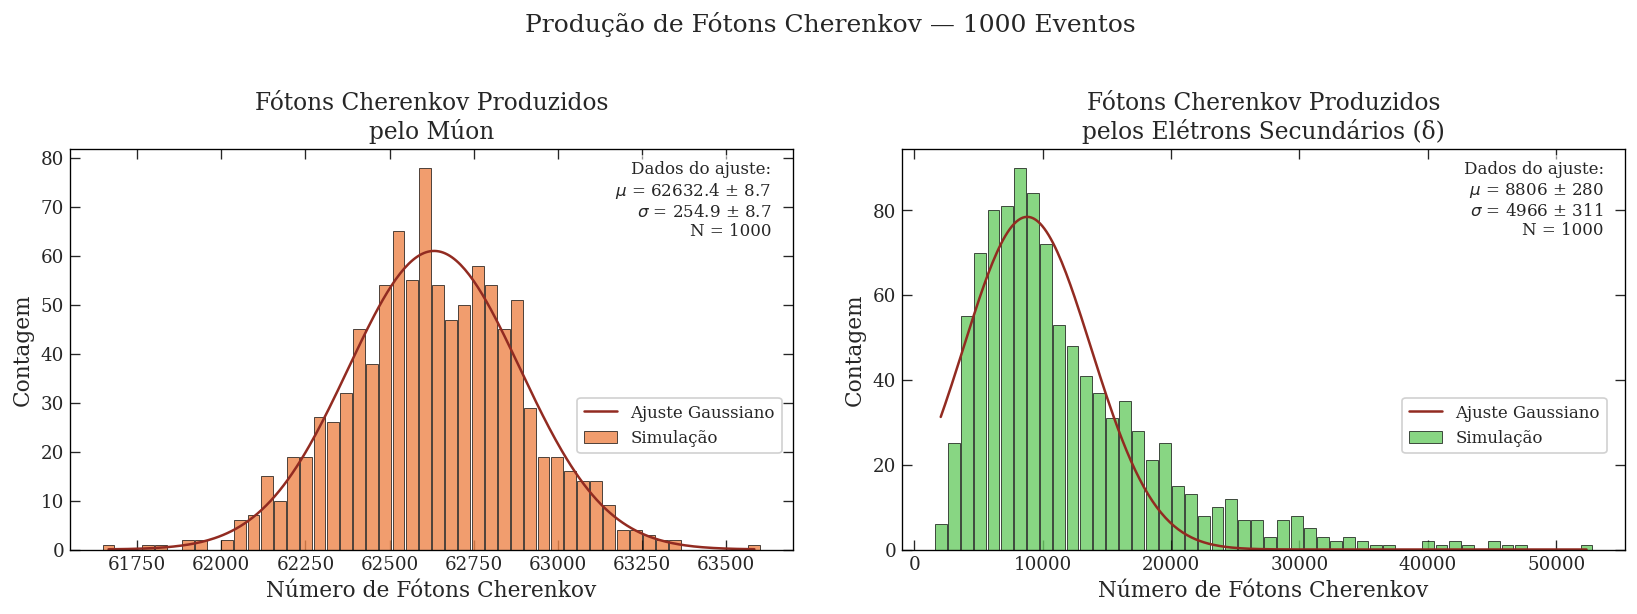

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
#palette = sns.color_palette('muted') #pastel

total = df['nCerenkovByMuon'] + df['nCerenkovByElectron']
fracao = df['nCerenkovByElectron'].mean() / total.mean() * 100

ax1 = axes[0]
fit_and_plot(ax1, df['nCerenkovByMuon'], bins=50, color=palette[1], fit_func='gaussian',
             text_x=0.97, text_y=0.97, text_ha='right')

ax1.set_xlabel('Número de Fótons Cherenkov')
ax1.set_ylabel('Contagem')
ax1.set_title('Fótons Cherenkov Produzidos\npelo Múon')
#ax1.legend(fontsize=10, loc='lower right')
ax1.legend(fontsize=10, bbox_to_anchor=(0.69, 0.4), loc='upper left')

ax2 = axes[1]
fit_and_plot(ax2, df['nCerenkovByElectron'], bins=50, color=palette[2], fit_func='gaussian',
             text_x=0.97, text_y=0.97, text_ha='right')
ax2.set_xlabel('Número de Fótons Cherenkov')
ax2.set_ylabel('Contagem')
ax2.set_title('Fótons Cherenkov Produzidos\npelos Elétrons Secundários (δ)')
#ax2.legend(fontsize=10)
ax2.legend(fontsize=10, bbox_to_anchor=(0.68, 0.4), loc='upper left')


# Caixa de estatísticas no canto inferior esquerdo do ax1
#stats_str = (
#    f'Múon:      {df["nCerenkovByMuon"].mean():.0f} ± {df["nCerenkovByMuon"].std():.0f}\n'
#    f'Elétrons:  {df["nCerenkovByElectron"].mean():.0f} ± {df["nCerenkovByElectron"].std():.0f}\n'
#    f'Fração e⁻: {fracao:.1f}%'
#)
#props = dict(boxstyle='round', facecolor='lightyellow', alpha=0.8)
#ax1.text(0.01, 0.93, stats_str, transform=ax1.transAxes, fontsize=9,
#         verticalalignment='bottom', horizontalalignment='left', bbox=props)

plt.suptitle('Produção de Fótons Cherenkov — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('cerenkov_producao.png')
plt.show()

## 5. Fótons Detectados pelas PMTs

Distribuição de fótons Cherenkov detectados por cada PMT após aplicação da eficiência quântica.

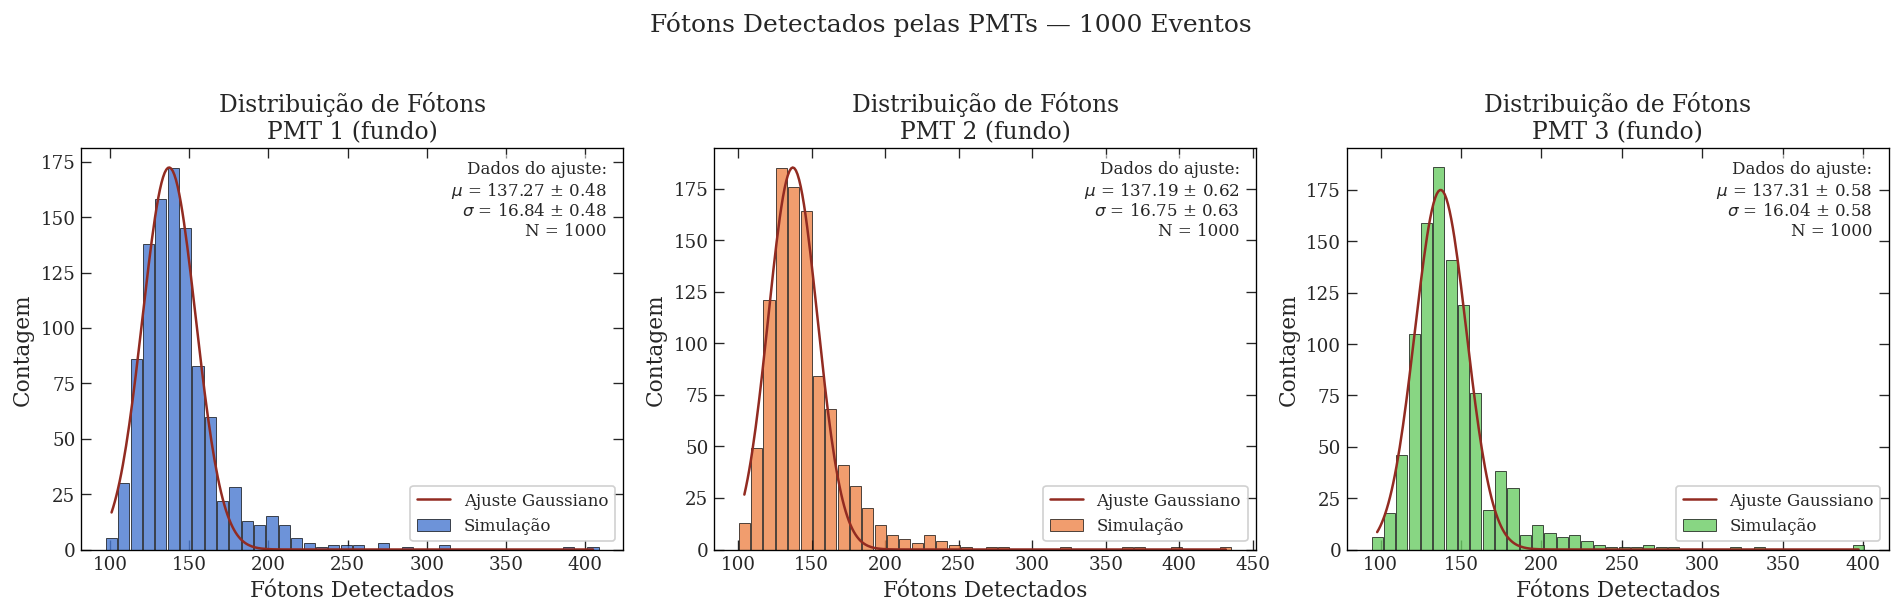

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
#palette = sns.color_palette('muted')
pmts = ['nFotonsPMT1', 'nFotonsPMT2', 'nFotonsPMT3']
labels = ['PMT 1 (fundo)', 'PMT 2 (fundo)', 'PMT 3 (fundo)']
colors = [palette[0], palette[1], palette[2]]

for ax, col, label, color in zip(axes, pmts, labels, colors):
    fit_and_plot(ax, df_pmt[col], bins=40, color=color, fit_func='gaussian')
    ax.set_xlabel('Fótons Detectados')
    ax.set_ylabel('Contagem')
    ax.set_title(f'Distribuição de Fótons\n{label}')
    #ax.legend(fontsize=9)
    ax.legend(fontsize=10, loc='lower right')

plt.suptitle('Fótons Detectados pelas PMTs — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('pmt_distribuicoes.png')
plt.show()

## 6. Comparação entre PMTs

Comparação da resposta das três PMTs do fundo — para um múon vertical central,
esperamos distribuições similares entre as PMTs (simetria azimutal).

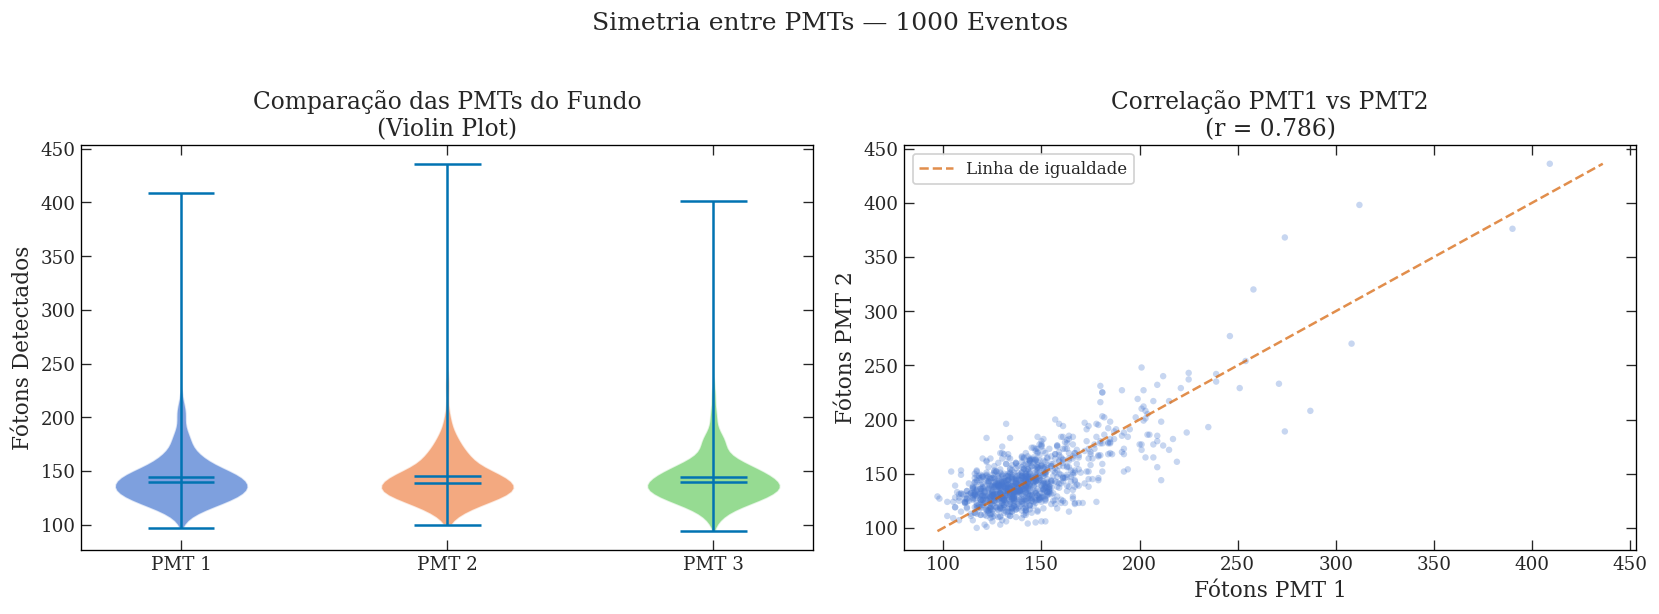

Médias por PMT:
  nFotonsPMT1: 145 ± 28
  nFotonsPMT2: 145 ± 29
  nFotonsPMT3: 145 ± 28


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = sns.color_palette('muted')

# Violin plot comparativo
ax1 = axes[0]
data_violin = [df_pmt['nFotonsPMT1'], df_pmt['nFotonsPMT2'], df_pmt['nFotonsPMT3']]
vp = ax1.violinplot(data_violin, positions=[1, 2, 3], showmeans=True, showmedians=True)
for i, pc in enumerate(vp['bodies']):
    pc.set_facecolor(palette[i])
    pc.set_alpha(0.7)
ax1.set_xticks([1, 2, 3])
ax1.set_xticklabels(['PMT 1', 'PMT 2', 'PMT 3'])
ax1.set_ylabel('Fótons Detectados')
ax1.set_title('Comparação das PMTs do Fundo\n(Violin Plot)')

# Correlação PMT1 vs PMT2
ax2 = axes[1]
ax2.scatter(df_pmt['nFotonsPMT1'], df_pmt['nFotonsPMT2'],
            alpha=0.3, s=15, color=palette[0], edgecolors='none')
# Linha diagonal
lim = [min(df_pmt['nFotonsPMT1'].min(), df_pmt['nFotonsPMT2'].min()),
       max(df_pmt['nFotonsPMT1'].max(), df_pmt['nFotonsPMT2'].max())]
ax2.plot(lim, lim, 'r--', linewidth=1.5, alpha=0.7, label='Linha de igualdade')
corr = df_pmt['nFotonsPMT1'].corr(df_pmt['nFotonsPMT2'])
ax2.set_xlabel('Fótons PMT 1')
ax2.set_ylabel('Fótons PMT 2')
ax2.set_title(f'Correlação PMT1 vs PMT2\n(r = {corr:.3f})')
ax2.legend(fontsize=10)

plt.suptitle('Simetria entre PMTs — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('pmt_comparacao.png')
plt.show()

print('Médias por PMT:')
for col in ['nFotonsPMT1', 'nFotonsPMT2', 'nFotonsPMT3']:
    print(f'  {col}: {df_pmt[col].mean():.0f} ± {df_pmt[col].std():.0f}')

## 7. Eficiência de Detecção

Comparação entre fótons produzidos (Cherenkov) e fótons detectados pelas PMTs.

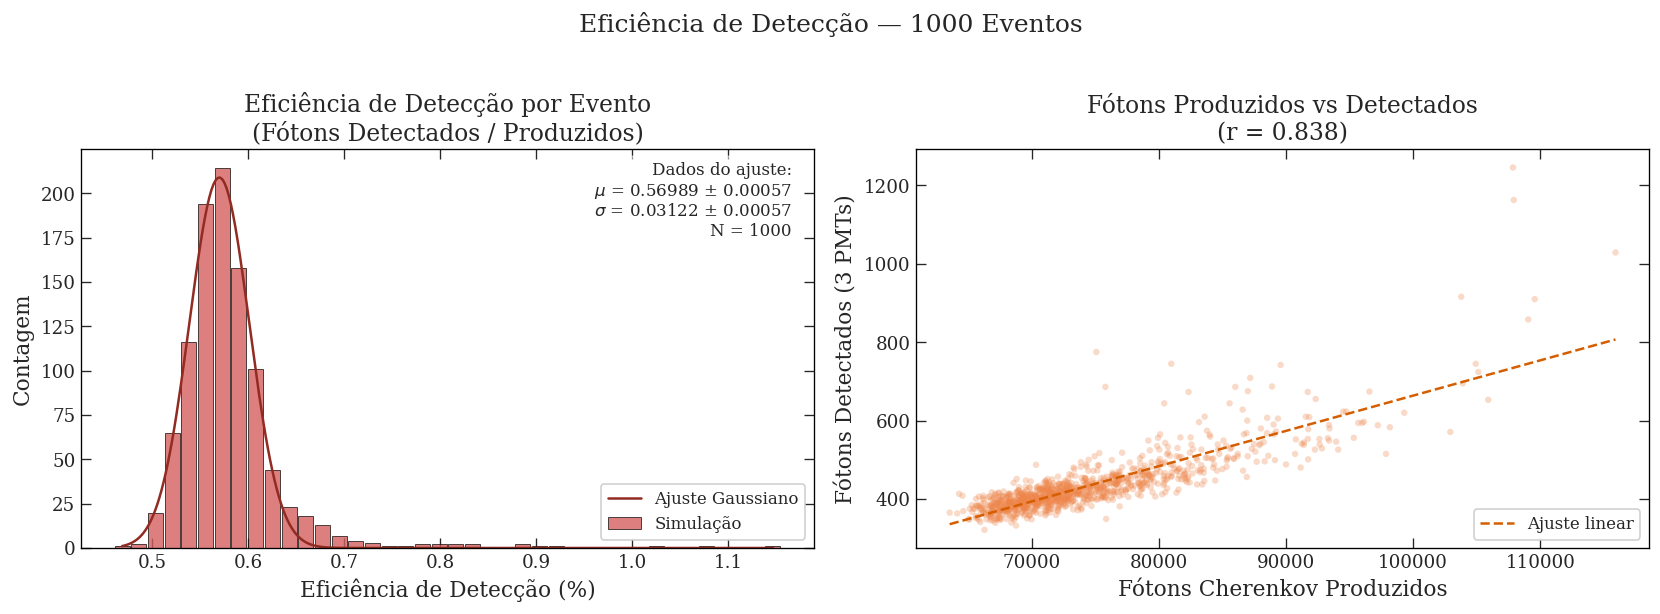

Eficiência média: 0.58% ± 0.06%
Total produzido (média): 74569
Total detectado (média): 435


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = sns.color_palette('muted')

# Eficiência por evento
df_all['eficiencia'] = df_all['nFotonsTotal'] / df_all['nCerenkovTotal'] * 100

ax1 = axes[0]
fit_and_plot(ax1, df_all['eficiencia'], bins=40, color=palette[3], fit_func='gaussian')
ax1.set_xlabel('Eficiência de Detecção (%)')
ax1.set_ylabel('Contagem')
ax1.set_title('Eficiência de Detecção por Evento\n(Fótons Detectados / Produzidos)')
#ax1.legend(fontsize=10)
ax1.legend(fontsize=10, loc='lower right')

# Correlação produzidos vs detectados
ax2 = axes[1]
ax2.scatter(df_all['nCerenkovTotal'], df_all['nFotonsTotal'],
            alpha=0.3, s=15, color=palette[1], edgecolors='none')
z = np.polyfit(df_all['nCerenkovTotal'], df_all['nFotonsTotal'], 1)
p = np.poly1d(z)
x_line = np.linspace(df_all['nCerenkovTotal'].min(), df_all['nCerenkovTotal'].max(), 100)
ax2.plot(x_line, p(x_line), 'r--', linewidth=1.5, label=f'Ajuste linear')
corr = df_all['nCerenkovTotal'].corr(df_all['nFotonsTotal'])
ax2.set_xlabel('Fótons Cherenkov Produzidos')
ax2.set_ylabel('Fótons Detectados (3 PMTs)')
ax2.set_title(f'Fótons Produzidos vs Detectados\n(r = {corr:.3f})')
#ax2.legend(fontsize=10)
ax2.legend(fontsize=10, loc='lower right')

plt.suptitle('Eficiência de Detecção — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('eficiencia_deteccao.png')
plt.show()

print(f'Eficiência média: {df_all["eficiencia"].mean():.2f}% ± {df_all["eficiencia"].std():.2f}%')
print(f'Total produzido (média): {df_all["nCerenkovTotal"].mean():.0f}')
print(f'Total detectado (média): {df_all["nFotonsTotal"].mean():.0f}')

## 8. Elétrons Secundários (Raios Delta)

Distribuição do número de elétrons delta produzidos pela ionização do múon.

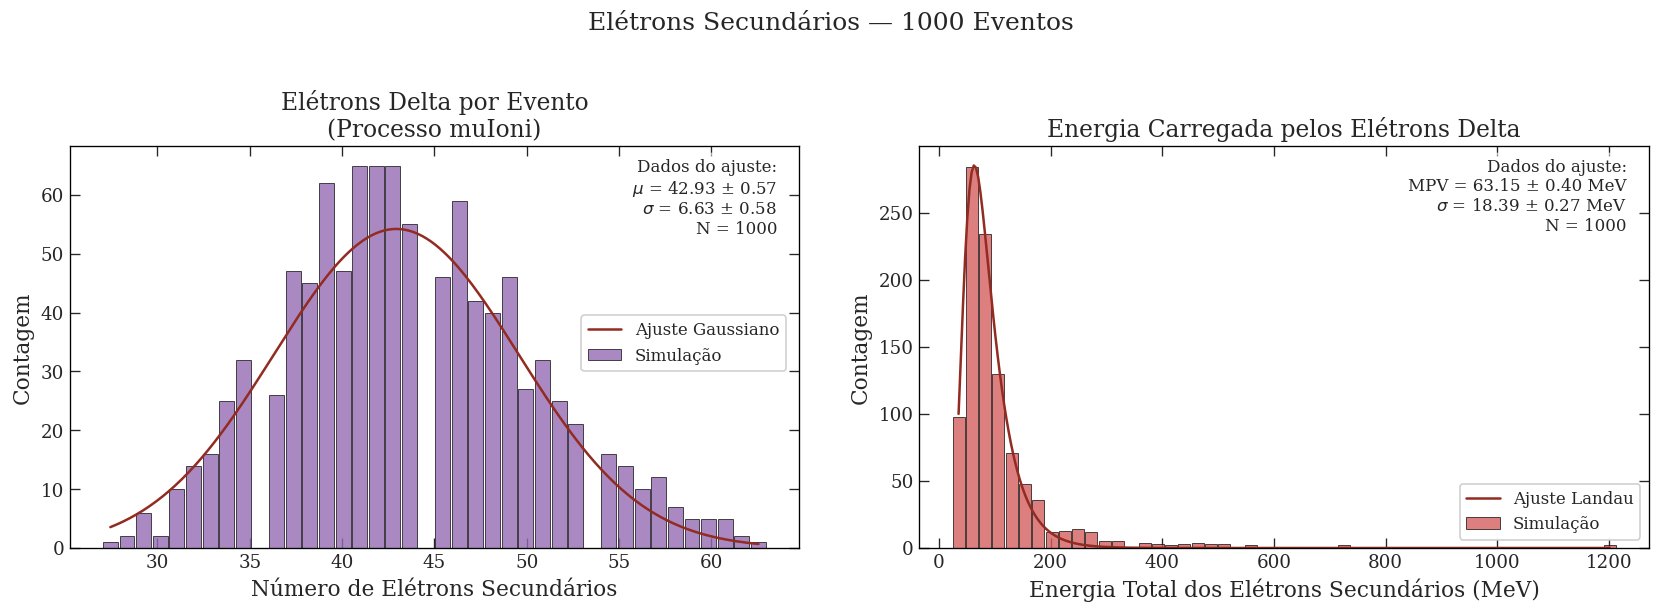

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = sns.color_palette('muted')

ax1 = axes[0]
fit_and_plot(ax1, df['nElectronSec'], bins=40, color=palette[4], fit_func='gaussian')
ax1.set_xlabel('Número de Elétrons Secundários')
ax1.set_ylabel('Contagem')
ax1.set_title('Elétrons Delta por Evento\n(Processo muIoni)')
#ax1.legend(fontsize=10)
 #ax1.legend(fontsize=10, loc='lower right')
ax1.legend(fontsize=10, bbox_to_anchor=(0.69, 0.6), loc='upper left')

ax2 = axes[1]
fit_and_plot(ax2, df['EnergyElectronSec_MeV'], bins=50, color=palette[3], fit_func='landau')
ax2.set_xlabel('Energia Total dos Elétrons Secundários (MeV)')
ax2.set_ylabel('Contagem')
ax2.set_title('Energia Carregada pelos Elétrons Delta')
#ax2.legend(fontsize=10)
ax2.legend(fontsize=10, loc='lower right')

plt.suptitle('Elétrons Secundários — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('eletrons_secundarios.png')
plt.show()

## 9. Correlações Físicas

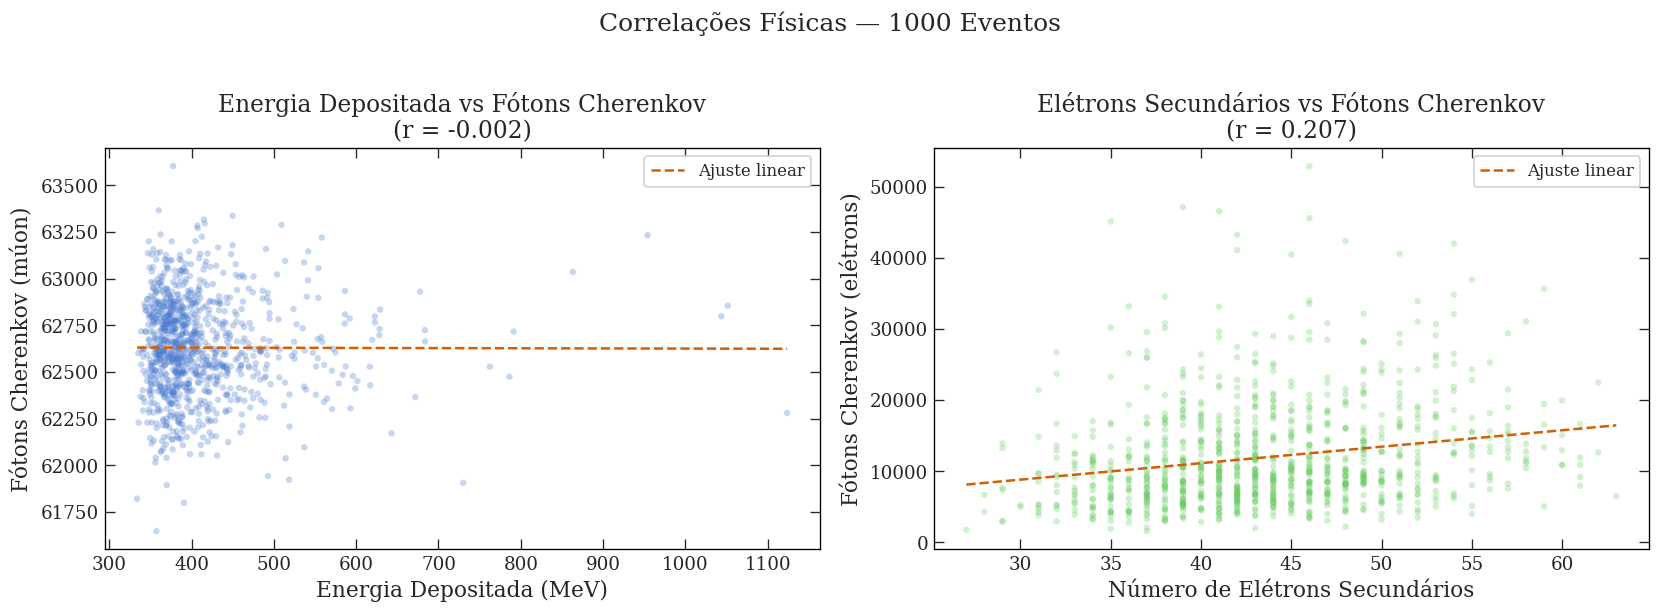

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = sns.color_palette('muted')

# Energia depositada vs fótons Cherenkov do múon
ax1 = axes[0]
ax1.scatter(df['EnergyDeposited_MeV'], df['nCerenkovByMuon'],
            alpha=0.3, s=15, color=palette[0], edgecolors='none')
z = np.polyfit(df['EnergyDeposited_MeV'], df['nCerenkovByMuon'], 1)
p = np.poly1d(z)
x_line = np.linspace(df['EnergyDeposited_MeV'].min(), df['EnergyDeposited_MeV'].max(), 100)
ax1.plot(x_line, p(x_line), 'r--', linewidth=1.5, label='Ajuste linear')
corr1 = df['EnergyDeposited_MeV'].corr(df['nCerenkovByMuon'])
ax1.set_xlabel('Energia Depositada (MeV)')
ax1.set_ylabel('Fótons Cherenkov (múon)')
ax1.set_title(f'Energia Depositada vs Fótons Cherenkov\n(r = {corr1:.3f})')
ax1.legend(fontsize=10)

# Elétrons secundários vs Cherenkov por elétrons
ax2 = axes[1]
ax2.scatter(df['nElectronSec'], df['nCerenkovByElectron'],
            alpha=0.3, s=15, color=palette[2], edgecolors='none')
z2 = np.polyfit(df['nElectronSec'], df['nCerenkovByElectron'], 1)
p2 = np.poly1d(z2)
x_line2 = np.linspace(df['nElectronSec'].min(), df['nElectronSec'].max(), 100)
ax2.plot(x_line2, p2(x_line2), 'r--', linewidth=1.5, label='Ajuste linear')
corr2 = df['nElectronSec'].corr(df['nCerenkovByElectron'])
ax2.set_xlabel('Número de Elétrons Secundários')
ax2.set_ylabel('Fótons Cherenkov (elétrons)')
ax2.set_title(f'Elétrons Secundários vs Fótons Cherenkov\n(r = {corr2:.3f})')
ax2.legend(fontsize=10)

plt.suptitle('Correlações Físicas — 1000 Eventos', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('correlacoes.png')
plt.show()

## 10. Resumo Físico da Simulação

In [10]:
resumo = pd.DataFrame({
    'Grandeza': [
        'Energia depositada (MeV)',
        'Fótons Cherenkov (múon)',
        'Fótons Cherenkov (elétrons)',
        'Total fótons Cherenkov produzidos',
        'Fração por elétrons (%)',
        'Elétrons secundários (N)',
        'Energia elétrons sec. (MeV)',
        'Fótons detectados PMT1',
        'Fótons detectados PMT2',
        'Fótons detectados PMT3',
        'Total detectado (3 PMTs)',
        'Eficiência de detecção (%)',
        'Deposição por gammas (MeV)',
    ],
    'Média': [
        df['EnergyDeposited_MeV'].mean(),
        df['nCerenkovByMuon'].mean(),
        df['nCerenkovByElectron'].mean(),
        df_all['nCerenkovTotal'].mean(),
        df['nCerenkovByElectron'].mean() / (df['nCerenkovByMuon'] + df['nCerenkovByElectron']).mean() * 100,
        df['nElectronSec'].mean(),
        df['EnergyElectronSec_MeV'].mean(),
        df_pmt['nFotonsPMT1'].mean(),
        df_pmt['nFotonsPMT2'].mean(),
        df_pmt['nFotonsPMT3'].mean(),
        df_pmt['nFotonsTotal'].mean(),
        df_all['eficiencia'].mean(),
        df['EdepGammas_MeV'].mean(),
    ],
    'Desvio Padrão': [
        df['EnergyDeposited_MeV'].std(),
        df['nCerenkovByMuon'].std(),
        df['nCerenkovByElectron'].std(),
        df_all['nCerenkovTotal'].std(),
        None,
        df['nElectronSec'].std(),
        df['EnergyElectronSec_MeV'].std(),
        df_pmt['nFotonsPMT1'].std(),
        df_pmt['nFotonsPMT2'].std(),
        df_pmt['nFotonsPMT3'].std(),
        df_pmt['nFotonsTotal'].std(),
        df_all['eficiencia'].std(),
        df['EdepGammas_MeV'].std(),
    ]
})

resumo = resumo.round(3)
print('=' * 60)
print('RESUMO FÍSICO DA SIMULAÇÃO SWGO')
print(f'Partícula: μ⁻ | Energia: 5 GeV | Direção: vertical')
print(f'Detector: WCD | Água: r=170cm, h=187.87cm | Tyvek')
print(f'Eventos simulados: {len(df)}')
print('=' * 60)
print(resumo.to_string(index=False))

RESUMO FÍSICO DA SIMULAÇÃO SWGO
Partícula: μ⁻ | Energia: 5 GeV | Direção: vertical
Detector: WCD | Água: r=170cm, h=187.87cm | Tyvek
Eventos simulados: 1000
                         Grandeza     Média  Desvio Padrão
         Energia depositada (MeV)   409.809         74.740
          Fótons Cherenkov (múon) 62629.845        259.172
      Fótons Cherenkov (elétrons) 11939.645       7346.364
Total fótons Cherenkov produzidos 74569.490       7347.296
          Fração por elétrons (%)    16.011            NaN
         Elétrons secundários (N)    43.564          6.574
      Energia elétrons sec. (MeV)   112.796        111.983
           Fótons detectados PMT1   144.644         28.214
           Fótons detectados PMT2   145.227         29.272
           Fótons detectados PMT3   144.762         28.105
         Total detectado (3 PMTs)   434.633         78.943
       Eficiência de detecção (%)     0.580          0.056
       Deposição por gammas (MeV)     0.057          0.092


## 11. Hodoscópio de Cintiladores

Distribuição dos hits no hodoscópio 32×32 pixels posicionado acima do WCD.
O múon vertical passa pelo pixel central antes de entrar no detector.

In [11]:
# Carrega dados do hodoscópio
df_hodo = pd.read_csv(HODO_PATH, comment='#', header=None, names=[
    'iEventID', 'ColumnID', 'RowID', 'Edep_MeV', 'Time_ns'
])

print(f'Hits no hodoscópio: {len(df_hodo)}')
print(f'\nPixels únicos atingidos:')
print(df_hodo.groupby(['ColumnID','RowID']).size().reset_index().rename(columns={0:'contagem'}))
print(f'\nEstatísticas da energia depositada:')
print(df_hodo['Edep_MeV'].describe().round(3))

Hits no hodoscópio: 1000

Pixels únicos atingidos:
   ColumnID  RowID  contagem
0        15     15       234
1        15     16       240
2        16     15       259
3        16     16       267

Estatísticas da energia depositada:
count    1000.000
mean        4.287
std         0.311
min         3.596
25%         4.071
50%         4.245
75%         4.462
max         5.776
Name: Edep_MeV, dtype: float64


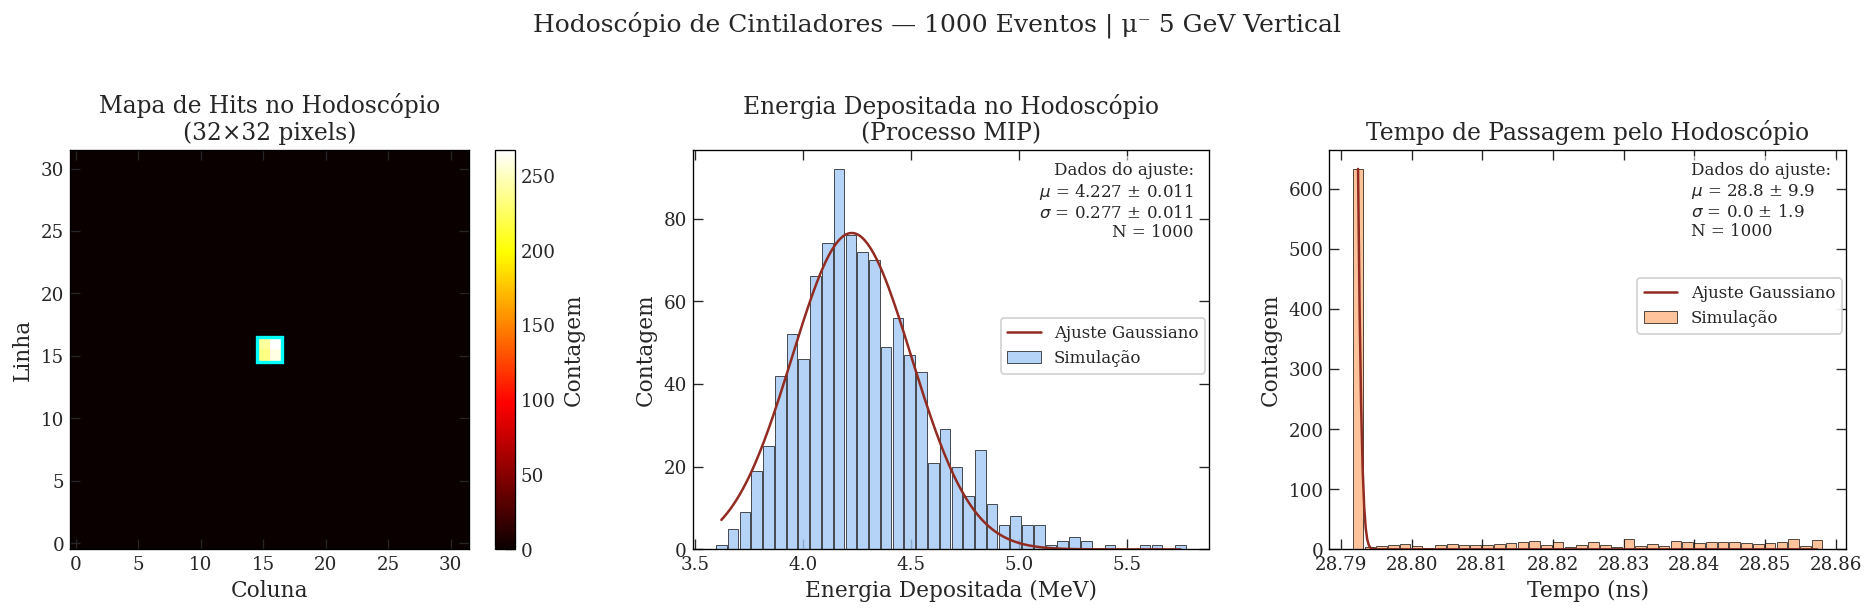

Pixel mais atingido: Coluna=16, Linha=16
Energia depositada: 4.287 ± 0.311 MeV
Tempo médio: 28.8055 ± 0.0214 ns


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
palette = sns.color_palette('pastel')

# Mapa de calor dos pixels atingidos
ax1 = axes[0]
heatmap = np.zeros((32, 32))
for _, row in df_hodo.iterrows():
    heatmap[int(row['RowID']), int(row['ColumnID'])] += 1
im = ax1.imshow(heatmap, cmap='hot', origin='lower')
plt.colorbar(im, ax=ax1, label='Contagem')
ax1.set_xlabel('Coluna')
ax1.set_ylabel('Linha')
ax1.set_title('Mapa de Hits no Hodoscópio\n(32×32 pixels)')
# Destaca região central
from matplotlib.patches import Rectangle
rect = Rectangle((14.5, 14.5), 2, 2, linewidth=2, edgecolor='cyan', facecolor='none')
ax1.add_patch(rect)

# Distribuição de energia depositada
ax2 = axes[1]
fit_and_plot(ax2, df_hodo['Edep_MeV'], bins=40, color=palette[0],
             fit_func='gaussian', text_x=0.97, text_y=0.97, text_ha='right')
ax2.set_xlabel('Energia Depositada (MeV)')
ax2.set_ylabel('Contagem')
ax2.set_title('Energia Depositada no Hodoscópio\n(Processo MIP)')
#ax2.legend(fontsize=10, loc='upper left')
ax2.legend(fontsize=10, bbox_to_anchor=(0.58, 0.6), loc='upper left')

# Distribuição do tempo
ax3 = axes[2]
fit_and_plot(ax3, df_hodo['Time_ns'], bins=40, color=palette[1],
             fit_func='gaussian', text_x=0.7, text_y=0.97, text_ha='left')
ax3.set_xlabel('Tempo (ns)')
ax3.set_ylabel('Contagem')
ax3.set_title('Tempo de Passagem pelo Hodoscópio')
 #ax3.legend(fontsize=10, loc='upper right')
ax3.legend(fontsize=10, bbox_to_anchor=(0.58, 0.7), loc='upper left')

plt.suptitle('Hodoscópio de Cintiladores — 1000 Eventos | μ⁻ 5 GeV Vertical', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('hodoscopio.png')
plt.show()

print(f'Pixel mais atingido: Coluna={df_hodo["ColumnID"].mode()[0]}, Linha={df_hodo["RowID"].mode()[0]}')
print(f'Energia depositada: {df_hodo["Edep_MeV"].mean():.3f} ± {df_hodo["Edep_MeV"].std():.3f} MeV')
print(f'Tempo médio: {df_hodo["Time_ns"].mean():.4f} ± {df_hodo["Time_ns"].std():.4f} ns')

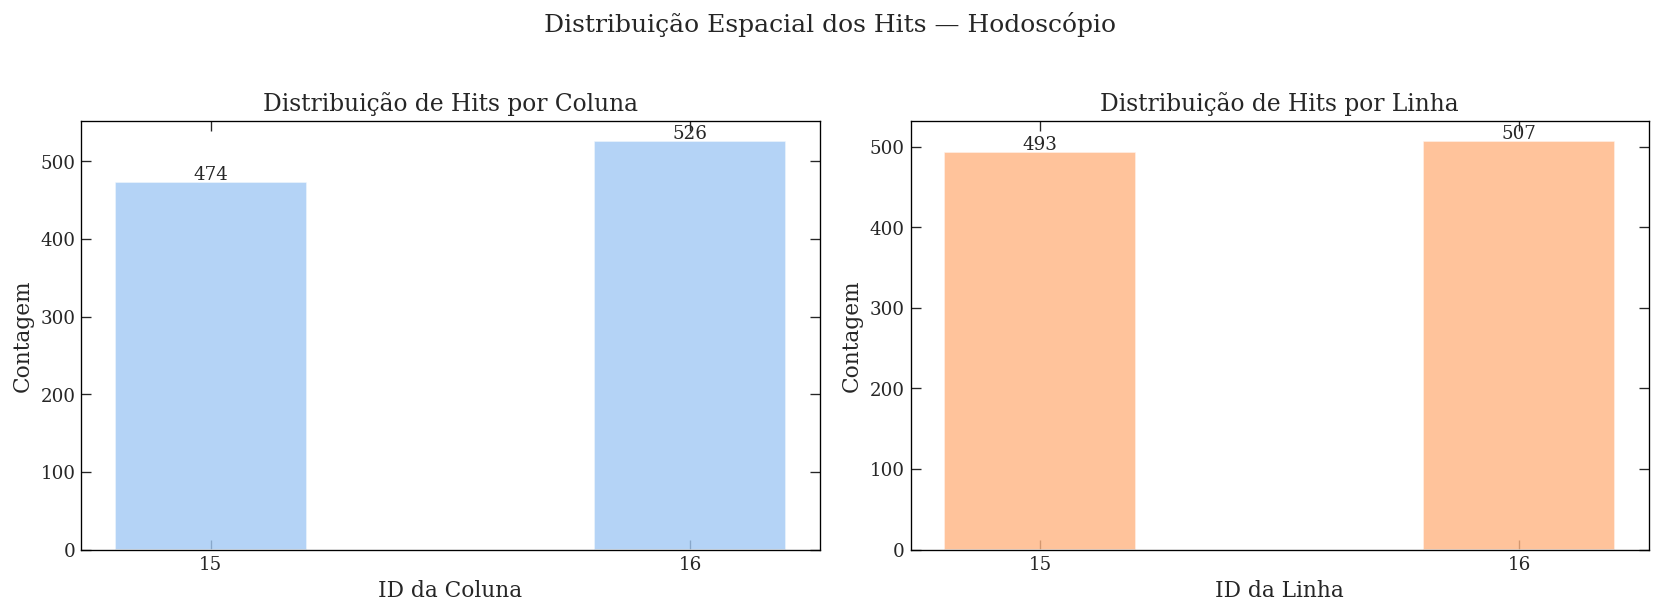


Contagem por pixel:
                contagem  edep_media  edep_std
ColumnID RowID                                
15       15          234       4.316     0.326
         16          240       4.272     0.289
16       15          259       4.279     0.315
         16          267       4.284     0.311


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = sns.color_palette('pastel')

# Distribuição por coluna
ax1 = axes[0]
col_counts = df_hodo['ColumnID'].value_counts().sort_index()
ax1.bar(col_counts.index, col_counts.values, color=palette[0], alpha=0.8, width=0.4)
ax1.set_xlabel('ID da Coluna')
ax1.set_ylabel('Contagem')
ax1.set_title('Distribuição de Hits por Coluna')
ax1.set_xticks(col_counts.index)
for x, y in zip(col_counts.index, col_counts.values):
    ax1.text(x, y + 3, str(y), ha='center', fontsize=11)

# Distribuição por linha  
ax2 = axes[1]
row_counts = df_hodo['RowID'].value_counts().sort_index()
ax2.bar(row_counts.index, row_counts.values, color=palette[1], alpha=0.8, width=0.4)
ax2.set_xlabel('ID da Linha')
ax2.set_ylabel('Contagem')
ax2.set_title('Distribuição de Hits por Linha')
ax2.set_xticks(row_counts.index)
for x, y in zip(row_counts.index, row_counts.values):
    ax2.text(x, y + 3, str(y), ha='center', fontsize=11)

plt.suptitle('Distribuição Espacial dos Hits — Hodoscópio', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('hodoscopio_pixels.png')
plt.show()

# Tabela de pixels atingidos
print('\nContagem por pixel:')
pixel_table = df_hodo.groupby(['ColumnID','RowID']).agg(
    contagem=('iEventID','count'),
    edep_media=('Edep_MeV','mean'),
    edep_std=('Edep_MeV','std')
).round(3)
print(pixel_table)

In [14]:
import numpy as np
from scipy.optimize import curve_fit

def landau_approx(x, A, mu, sigma):
    lam = (x - mu) / sigma
    return A * np.exp(-0.5 * (lam + np.exp(-lam))) / np.sqrt(2 * np.pi)

def gaussian(x, A, mu, sigma):
    return A * np.exp(-0.5 * ((x - mu) / sigma) ** 2)

# Landau - Edep
edep = df['EnergyDeposited_MeV']
edep_f = edep[edep < edep.mean() + 3*edep.std()]
counts, edges = np.histogram(edep_f, bins=60)
centers = (edges[:-1]+edges[1:])/2
popt, pcov = curve_fit(landau_approx, centers, counts, p0=[counts.max(), edep_f.mean(), edep_f.std()], maxfev=5000)
perr = np.sqrt(np.diag(pcov))
print(f'Landau Edep: MPV = {popt[1]:.2f} ± {perr[1]:.2f} MeV, σ = {abs(popt[2]):.2f} ± {perr[2]:.2f} MeV, outliers={len(edep)-len(edep_f)}')

# Gaussiana - Cherenkov muon
counts2, edges2 = np.histogram(df['nCerenkovByMuon'], bins=50)
centers2 = (edges2[:-1]+edges2[1:])/2
popt2, pcov2 = curve_fit(gaussian, centers2, counts2, p0=[counts2.max(), df['nCerenkovByMuon'].mean(), df['nCerenkovByMuon'].std()], maxfev=5000)
perr2 = np.sqrt(np.diag(pcov2))
print(f'Gauss Cer muon: μ = {popt2[1]:.1f} ± {perr2[1]:.1f}, σ = {abs(popt2[2]):.1f} ± {perr2[2]:.1f}')

# Gaussiana - Cherenkov elétrons
counts3, edges3 = np.histogram(df['nCerenkovByElectron'], bins=50)
centers3 = (edges3[:-1]+edges3[1:])/2
popt3, pcov3 = curve_fit(gaussian, centers3, counts3, p0=[counts3.max(), df['nCerenkovByElectron'].mean(), df['nCerenkovByElectron'].std()], maxfev=5000)
perr3 = np.sqrt(np.diag(pcov3))
print(f'Gauss Cer elet: μ = {popt3[1]:.1f} ± {perr3[1]:.1f}, σ = {abs(popt3[2]):.1f} ± {perr3[2]:.1f}')

# Gaussiana - PMTs
for col in ['nFotonsPMT1','nFotonsPMT2','nFotonsPMT3']:
    counts4, edges4 = np.histogram(df_pmt[col], bins=40)
    centers4 = (edges4[:-1]+edges4[1:])/2
    popt4, pcov4 = curve_fit(gaussian, centers4, counts4, p0=[counts4.max(), df_pmt[col].mean(), df_pmt[col].std()], maxfev=5000)
    perr4 = np.sqrt(np.diag(pcov4))
    print(f'Gauss {col}: μ = {popt4[1]:.1f} ± {perr4[1]:.1f}, σ = {abs(popt4[2]):.1f} ± {perr4[2]:.1f}')

# Gaussiana eficiência
df_all['eficiencia'] = df_all['nFotonsTotal'] / df_all['nCerenkovTotal'] * 100
counts5, edges5 = np.histogram(df_all['eficiencia'], bins=40)
centers5 = (edges5[:-1]+edges5[1:])/2
popt5, pcov5 = curve_fit(gaussian, centers5, counts5, p0=[counts5.max(), df_all['eficiencia'].mean(), df_all['eficiencia'].std()], maxfev=5000)
perr5 = np.sqrt(np.diag(pcov5))
print(f'Gauss efic: μ = {popt5[1]:.4f} ± {perr5[1]:.4f}%, σ = {abs(popt5[2]):.4f} ± {perr5[2]:.4f}%')

# Gaussiana elétrons delta número
counts6, edges6 = np.histogram(df['nElectronSec'], bins=40)
centers6 = (edges6[:-1]+edges6[1:])/2
popt6, pcov6 = curve_fit(gaussian, centers6, counts6, p0=[counts6.max(), df['nElectronSec'].mean(), df['nElectronSec'].std()], maxfev=5000)
perr6 = np.sqrt(np.diag(pcov6))
print(f'Gauss nElec: μ = {popt6[1]:.2f} ± {perr6[1]:.2f}, σ = {abs(popt6[2]):.2f} ± {perr6[2]:.2f}')

# Landau energia elétrons
edep_e = df['EnergyElectronSec_MeV']
edep_ef = edep_e[edep_e < edep_e.mean() + 3*edep_e.std()]
counts7, edges7 = np.histogram(edep_ef, bins=50)
centers7 = (edges7[:-1]+edges7[1:])/2
popt7, pcov7 = curve_fit(landau_approx, centers7, counts7, p0=[counts7.max(), edep_ef.mean(), edep_ef.std()], maxfev=5000)
perr7 = np.sqrt(np.diag(pcov7))
print(f'Landau Eelec: MPV = {popt7[1]:.2f} ± {perr7[1]:.2f} MeV, σ = {abs(popt7[2]):.2f} ± {perr7[2]:.2f} MeV')

# Correlações
corr1 = df['EnergyDeposited_MeV'].corr(df['nCerenkovByMuon'])
corr2 = df['nElectronSec'].corr(df['nCerenkovByElectron'])
corr3 = df_all['nCerenkovTotal'].corr(df_all['nFotonsTotal'])
corr4 = df_pmt['nFotonsPMT1'].corr(df_pmt['nFotonsPMT2'])
print(f'r(Edep, CerMuon) = {corr1:.3f}')
print(f'r(nElec, CerElec) = {corr2:.3f}')
print(f'r(CerTotal, PMTtotal) = {corr3:.3f}')
print(f'r(PMT1, PMT2) = {corr4:.3f}')

Landau Edep: MPV = 371.28 ± 0.68 MeV, σ = 17.30 ± 0.51 MeV, outliers=14
Gauss Cer muon: μ = 62632.4 ± 8.7, σ = 254.9 ± 8.7
Gauss Cer elet: μ = 8806.4 ± 280.4, σ = 4965.9 ± 310.7
Gauss nFotonsPMT1: μ = 137.3 ± 0.5, σ = 16.8 ± 0.5
Gauss nFotonsPMT2: μ = 137.2 ± 0.6, σ = 16.7 ± 0.6
Gauss nFotonsPMT3: μ = 137.3 ± 0.6, σ = 16.0 ± 0.6
Gauss efic: μ = 0.5699 ± 0.0006%, σ = 0.0312 ± 0.0006%
Gauss nElec: μ = 42.93 ± 0.57, σ = 6.63 ± 0.58
Landau Eelec: MPV = 62.15 ± 0.71 MeV, σ = 17.13 ± 0.53 MeV
r(Edep, CerMuon) = -0.002
r(nElec, CerElec) = 0.207
r(CerTotal, PMTtotal) = 0.838
r(PMT1, PMT2) = 0.786
